<b>Testing SMOTE with the infamous red wine dataset</b>

In [185]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

# Load the Wine Quality dataset
df = pd.read_csv("../../winequality-red.csv")

Original class distribution:
quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


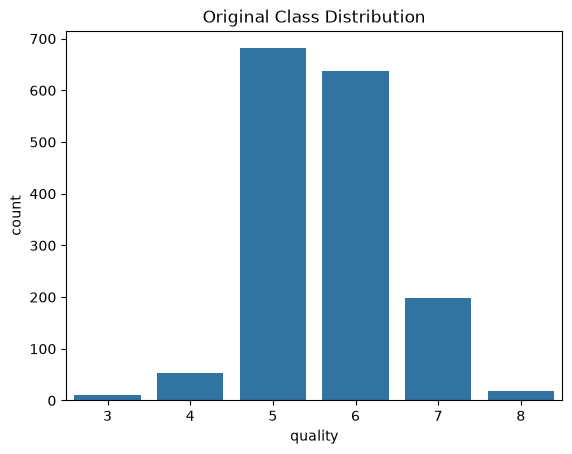

In [186]:
# Display original class distribution
print("Original class distribution:")
print(df['quality'].value_counts())

# Visualize original distribution
sns.countplot(x='quality', data=df)
plt.title('Original Class Distribution')
plt.show()

In [187]:
# Separate features and target
X = df.drop('quality', axis=1)
y = df['quality']

# if you want, you can also introduce a sampling strategy
# smote = SMOTE(sampling_strategy='minority', random_state=42)
# smote = SMOTE(sampling_strategy={3: 300, 4: 400, 5: 681, 6: 638, 7: 400, 8:300}, random_state=22)

# Apply SMOTE to the dataset
smote = SMOTE()

# use smote to sample a new version
X_resampled, y_resampled = smote.fit_resample(X, y)

# Combine resampled features and target into a new DataFrame
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled['quality'] = y_resampled

New class distribution after SMOTE:
quality
5    681
6    681
7    681
4    681
8    681
3    681
Name: count, dtype: int64


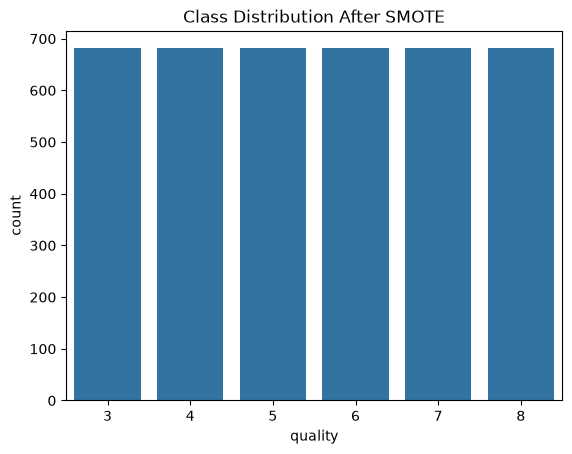

In [188]:
# Display new class distribution
print("New class distribution after SMOTE:")
print(df_resampled['quality'].value_counts())

# Visualize new distribution
sns.countplot(x='quality', data=df_resampled)
plt.title('Class Distribution After SMOTE')
plt.show()

In [189]:
df.duplicated().sum()

np.int64(240)

In [190]:
df_resampled.duplicated().sum()

np.int64(288)

<b>Comparing the details with the original and new dataframe, surprisingly good</b>>

<b>All in all, this should be now tested with a machine learning model, does it work any better?</b>

In [191]:
df.corr(numeric_only=True)['quality'].sort_values(ascending=True)

volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
quality                 1.000000
Name: quality, dtype: float64

In [ ]:
# the SMOTE seems to emphasize more certain variables
# the original distribution was horrible, so that might be the reason
df_resampled.corr(numeric_only=True)['quality'].sort_values(ascending=True)

volatile acidity       -0.676194
chlorides              -0.342945
density                -0.332921
pH                     -0.315752
residual sugar         -0.037077
total sulfur dioxide    0.033165
free sulfur dioxide     0.089998
fixed acidity           0.153689
sulphates               0.435315
citric acid             0.441029
alcohol                 0.632187
quality                 1.000000
Name: quality, dtype: float64

In [193]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [194]:
df_resampled.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000,4086.000000
mean,8.353799,0.582923,0.274239,2.588092,0.089439,13.514565,36.715162,0.996523,3.327620,0.659836,10.714744,5.500000
std,1.624808,0.245922,0.201336,1.195781,0.046247,9.640131,28.270260,0.001875,0.153130,0.158956,1.172595,1.708034
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.200000,0.387871,0.076828,1.959493,0.069886,5.907366,15.578942,0.995365,3.218663,0.550461,9.800000,4.000000
50%,8.000000,0.540000,0.270000,2.200000,0.078661,11.000000,27.847775,0.996549,3.320000,0.630000,10.565394,5.500000
75%,9.400000,0.715000,0.440000,2.755197,0.092000,18.000000,48.000000,0.997620,3.424944,0.746275,11.499978,7.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [195]:
df.var(numeric_only=True)

fixed acidity              3.031416
volatile acidity           0.032062
citric acid                0.037947
residual sugar             1.987897
chlorides                  0.002215
free sulfur dioxide      109.414884
total sulfur dioxide    1082.102373
density                    0.000004
pH                         0.023835
sulphates                  0.028733
alcohol                    1.135647
quality                    0.652168
dtype: float64

In [ ]:
# some changes here also, it seems
df_resampled.var(numeric_only=True)

fixed acidity             2.640000
volatile acidity          0.060478
citric acid               0.040536
residual sugar            1.429891
chlorides                 0.002139
free sulfur dioxide      92.932134
total sulfur dioxide    799.207611
density                   0.000004
pH                        0.023449
sulphates                 0.025267
alcohol                   1.374978
quality                   2.917381
dtype: float64